In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
%matplotlib inline
import random
from tqdm.notebook import tqdm
import seaborn as sns
from qpsolvers import solve_qp
from itertools import product
from skophys.preprocessing import Vectorizer, UnVectorizer

wgpu version from git (0.15.3) and __version__ (0.19.3) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.
WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


Incompatible version of wgpu:
    Detected 0.15.3.post97+g8a0b267, need >=(0, 19, 0), <(0, 20, 0).
    To update, use e.g. `pip install -U wgpu`.
/home/kushal/venvs/fpl/lib64/python3.12/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: float,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg,
        interp_factor: int = 2,
        firing_prop: float = 0.005,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: float

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * interp_factor))

    x = 0
    a = 0.7

    b = 0

    spikes = list()

    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (1 * spikes[c_ix][i])

        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

In [4]:
k = 10
firing_prop = 0.05

X, _ = generate_data(
    n_timepoints=5_000,
    n_components=k,
    noise=0,
    n_pixels=1,
    n_pixels_bg=0,
    interp_factor=1,
    firing_prop=firing_prop,
)

<Axes: >

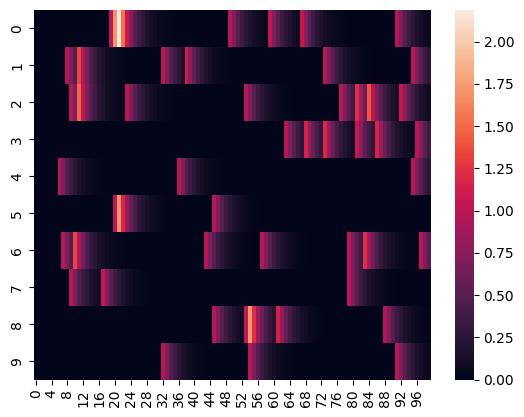

In [5]:
sns.heatmap(X[:, :100])

In [6]:
def gaus2d(x=0, y=0, mx=0, my=0, sx=1, sy=1):
    return 1. / (2. * np.pi * sx * sy) * np.exp(-((x - mx)**2. / (2. * sx**2.) + (y - my)**2. / (2. * sy**2.)))

r = -20, 20
r = np.linspace(*r)
x, y = np.meshgrid(r, r)
z = gaus2d(x, y)[20:-20, 20:-20]
z /= z.max()

In [7]:
z.min()

np.float64(1.6286158240184545e-06)

<Axes: >

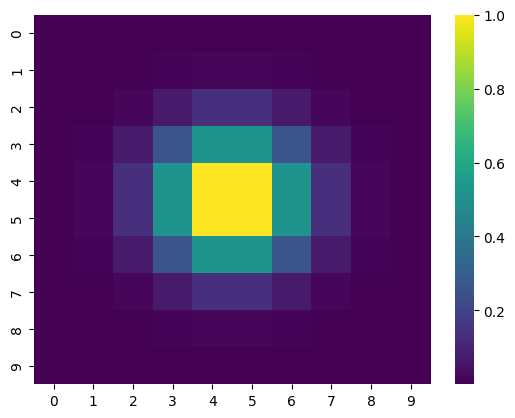

In [8]:
sns.heatmap(z, cmap="viridis")

In [9]:
dims = 32, 32

In [10]:
z.shape

(10, 10)

Example layouts:

0: well spread out

1: lots of overlaps

2, 4, 5, 6: some overlaps, realistic

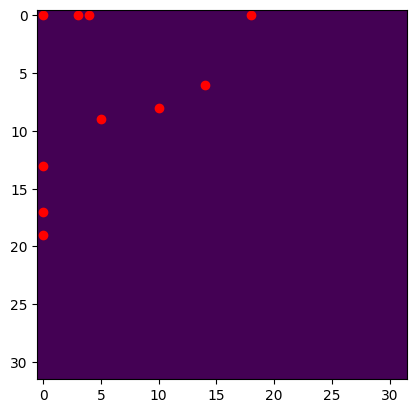

In [131]:
np.random.seed(5)
locs = (np.random.rand(10, 2) * dims[0] - z.shape[0]).clip(0).astype(int)

plt.imshow(np.zeros(dims))
plt.scatter(locs[:, 0], locs[:, 1], c="r")
plt.show()

In [132]:
slice(0, *((start, None) for start in locs[0]))

slice(0, (np.int64(0), None), (np.int64(17), None))

In [133]:
A = np.zeros((k, *dims))

In [134]:
for i in range(k):
    xs = slice(locs[i, 0], locs[i, 0] + 10)
    ys = slice(locs[i, 1], locs[i, 1] + 10)
    A[i, ys, xs] = z

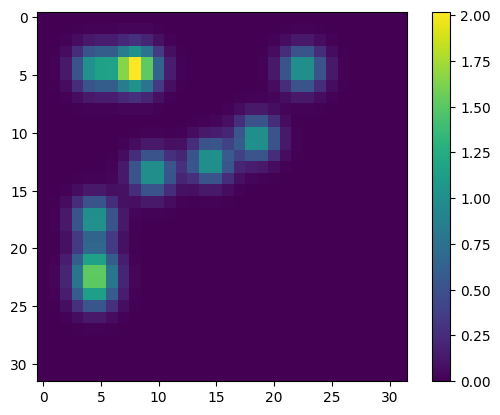

In [135]:
plt.imshow(A.sum(axis=0))
plt.colorbar()

In [136]:
A = A.reshape(k, np.prod(dims))
A.shape

(10, 1024)

In [137]:
X.shape

(10, 5000)

In [138]:
movie = (A.T @ X).reshape(*dims, X.shape[1]).transpose(-1, 0, 1)

In [139]:
movie.shape

(5000, 32, 32)

In [140]:
frame_sums = movie.sum(axis=(1, 2))
frame_sums /= frame_sums.max()
frame_sums *= (movie.max() / 10)

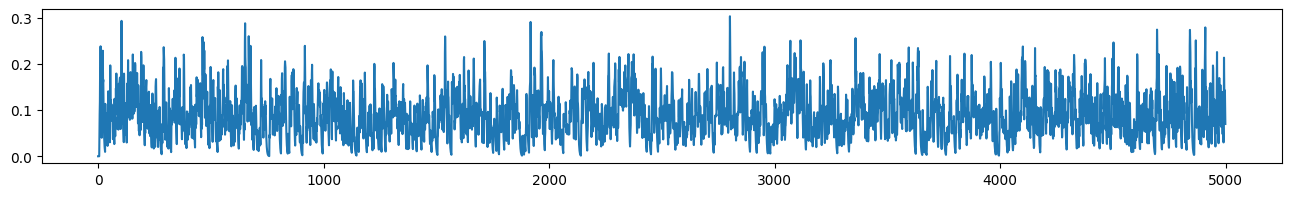

In [141]:
fig = plt.figure(figsize=(16, 2))
plt.plot(frame_sums)
plt.show()

In [142]:
np.random.seed(0)
noise = np.random.normal(scale=0.05, size=np.prod(movie.shape)).reshape(movie.shape)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
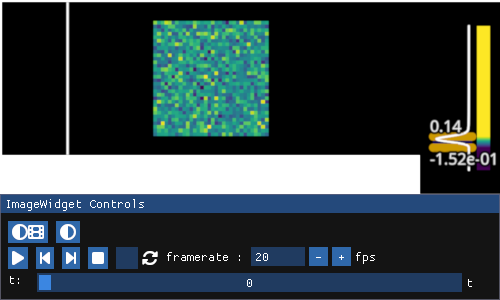

In [143]:
fpl.ImageWidget(movie + frame_sums[:, None, None] + noise, cmap="viridis").show()

In [144]:
def sim_matching_init(X_init, k, error) -> tuple[np.ndarray, np.ndarray, int]:
    """
    Returns
    -------
        W, M, n_iter
    """
    cov = X_init.T @ X_init
    XTX = cov / np.linalg.norm(cov, ord="fro")
    
    T = XTX.shape[0]

    eta = 1e-1
    
    Y = (np.random.randn(k, T) / np.sqrt(T)).clip(0)

    for n_iter in tqdm(range(50_000)):
        Y_old = Y
        Y = Y + eta * Y @ (XTX - Y.T @ Y)
        
        zeroed = Y.sum(axis=1) == 0.0
        Y[zeroed] = (np.random.randn(zeroed.sum(), T) / np.sqrt(T)).clip(0)
        
        Y = Y.clip(0)
    
        er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta
    
        if er < error:
            break
            
    W = Y @ X_init.T
    M = Y @ Y.T

    return W, M, n_iter

In [145]:
movie.shape

(5000, 32, 32)

In [146]:
X_init = Vectorizer().transform(movie)[:, :1000]
unvec = UnVectorizer(movie.shape[1:])

In [147]:
W, M, n_iter = sim_matching_init(X_init, k, 1e-4)

  0%|          | 0/50000 [00:00<?, ?it/s]

In [148]:
def solve_yt(x_t, Wt, Mt, k):
    return solve_qp(
        (Mt + Mt.T) / 2,
        -Wt @ x_t,
        lb=np.zeros(k),
        solver="cvxopt"
    )

In [149]:
X_diag = np.diag(np.ones(X_init.shape[0]))

F = np.zeros((k, X_init.shape[0]))

for i in range(X_init.shape[0]):
    F[:, i] = solve_yt(X_diag[:, i], W, M, k)

F /= F.sum(axis=1)[:, None]

In [150]:
F.shape

(10, 1024)

In [151]:
unvec.transform(F.T).shape

(10, 32, 32)

In [152]:
from skophys.viz_helpers import spatial_to_rgba

In [153]:
F_rgba = spatial_to_rgba(unvec.transform(F.T), 90)

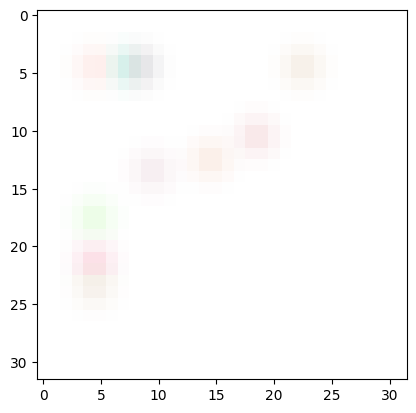

In [154]:
for c in F_rgba:
    plt.imshow(c)

plt.show()

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
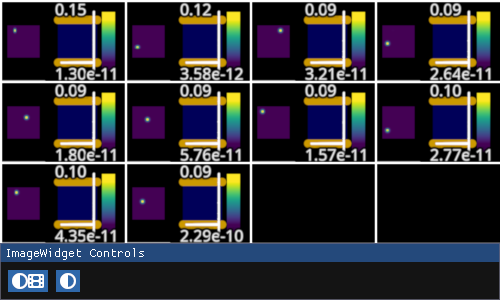

In [155]:
iw_F = fpl.ImageWidget([a for a in unvec.transform(F.T)], cmap="viridis")

for sp in iw_F.figure:
    sp.toolbar = False

iw_F.show()